# Instacart Market Basket Analysis: Exploratory Data Analysis

An exploratory analysis of about 3.4 million grocery orders from the *Instacart Online Grocery Shopping Dataset (2017)*.
The goal is to understand **when** customers shop, **how often** they come back, and **what** they buy and re-buy.

**Questions answered**

1. When do customers order? Which days and hours are busiest?
2. How often do users order, how big are their baskets, and how long do they wait between orders?
3. How does the reorder rate change by time of day, department and position in the cart?
4. Which products, aisles and departments dominate?


`orders.csv`, `order_products__prior.csv`, `products.csv`, `aisles.csv`, `departments.csv`. The data is not included in this repository.



## 1. Setup

In [1]:


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# Plot style
plt.rcParams.update({"axes.grid": True, "grid.color": "#e5e5e5", "axes.axisbelow": True})
plt.rcParams.update({"axes.titleweight": "bold", "axes.titlesize": 13, "figure.dpi": 100})
BLUE, ORANGE, GREY = "#3d5a80", "#e07a5f", "#9a9a9a"


### Analysis settings

**Day-of-week encoding.** The dataset documents `order_dow` only as 0-6 and does not say which day is 0.
This notebook *assumes* `0 = Saturday` and `1 = Sunday`, which matches the pattern of the two busiest days.
If your source says otherwise, change `DOW_LABELS` once and every chart and statistic below updates.

**Time of day.** Hours are grouped into four periods: Night (0-4), Morning (5-11), Afternoon (12-17) and Evening (18-23).

## 2. Load and validate the data

Integer columns are loaded with compact dtypes. This cuts memory use by roughly two thirds compared with the pandas default (int64),
which matters because `order_products__prior.csv` has 32 million rows.

In [2]:
order_products = pd.read_csv("C:/Users/HP/Downloads/instamart/order_products__prior.csv")
orders = pd.read_csv("C:/Users/HP/Downloads/instamart/orders.csv")
products = pd.read_csv("C:/Users/HP/Downloads/instamart/products.csv")
aisles = pd.read_csv("C:/Users/HP/Downloads/instamart/aisles.csv")
departments = pd.read_csv("C:/Users/HP/Downloads/instamart/departments.csv")




### Data information

The checks below were collected from the first notebook, one group per table.
In that notebook the order-products table was called `instamart`; here it is `order_products`, the name used in the rest of this notebook.

#### `orders`

In [3]:
orders.head()

,order_id,user_id,eval_set,order_number,order_dow,order_hour_of_day,days_since_prior_order
0,2539329,1,prior,1,2,8,NaN
1,2398795,1,prior,2,3,7,15.0
2,473747,1,prior,3,3,12,21.0
3,2254736,1,prior,4,4,7,29.0
4,431534,1,prior,5,4,15,28.0


In [4]:
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 3421083 entries, 0 to 3421082
Data columns (total 7 columns):
 #   Column                  Dtype  
---  ------                  -----  
 0   order_id                int64  
 1   user_id                 int64  
 2   eval_set                str    
 3   order_number            int64  
 4   order_dow               int64  
 5   order_hour_of_day       int64  
 6   days_since_prior_order  float64
dtypes: float64(1), int64(5), str(1)
memory usage: 182.7 MB


#### `order_products` (order_products__prior)

In [5]:
order_products.head()

,order_id,product_id,add_to_cart_order,reordered
0,2,33120,1,1
1,2,28985,2,1
2,2,9327,3,0
3,2,45918,4,1
4,2,30035,5,0


In [6]:
order_products.info()

<class 'pandas.DataFrame'>
RangeIndex: 32434489 entries, 0 to 32434488
Data columns (total 4 columns):
 #   Column             Dtype
---  ------             -----
 0   order_id           int64
 1   product_id         int64
 2   add_to_cart_order  int64
 3   reordered          int64
dtypes: int64(4)
memory usage: 989.8 MB


In [7]:
order_products.isnull().sum()

order_id             0
product_id           0
add_to_cart_order    0
reordered            0
dtype: int64

In [8]:
# ASSUMPTION: 0 = Saturday, 1 = Sunday (not documented in the dataset). Edit here if needed.
DOW_LABELS = {0: "Sat", 1: "Sun", 2: "Mon", 3: "Tue", 4: "Wed", 5: "Thu", 6: "Fri"}
WEEKEND_CODES = [0, 1]
SATURDAY = 0
DAY_ORDER = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
WEEKEND_DAYS = {DOW_LABELS[c] for c in WEEKEND_CODES}

PERIOD_BINS = [-1, 4, 11, 17, 23]
PERIOD_LABELS = ["Night (0-4)", "Morning (5-11)", "Afternoon (12-17)", "Evening (18-23)"]


def to_period(hours):
    """Map hour-of-day values (0-23) to a named period of the day."""
    return pd.cut(hours, bins=PERIOD_BINS, labels=PERIOD_LABELS)


# Placeholder departments in the source data (not real categories)
PLACEHOLDER_DEPTS = ["missing", "other"]

#### `products`

In [9]:
products.head()

,product_id,product_name,aisle_id,department_id
0,1,Chocolate Sandwich Cookies,61,19
1,2,All-Seasons Salt,104,13
2,3,Robust Golden Unsweetened Oolong Tea,94,7
3,4,Smart Ones Classic Favorites Mini Rigatoni Wit...,38,1
4,5,Green Chile Anytime Sauce,5,13


In [10]:
products.info()

<class 'pandas.DataFrame'>
RangeIndex: 49688 entries, 0 to 49687
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   product_id     49688 non-null  int64
 1   product_name   49688 non-null  str  
 2   aisle_id       49688 non-null  int64
 3   department_id  49688 non-null  int64
dtypes: int64(3), str(1)
memory usage: 1.5 MB


In [11]:
products.isnull().sum()

product_id       0
product_name     0
aisle_id         0
department_id    0
dtype: int64

#### `aisles`

In [12]:
aisles.head()

,aisle_id,aisle
0,1,prepared soups salads
1,2,specialty cheeses
2,3,energy granola bars
3,4,instant foods
4,5,marinades meat preparation


In [13]:
aisles.info()

<class 'pandas.DataFrame'>
RangeIndex: 134 entries, 0 to 133
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   aisle_id  134 non-null    int64
 1   aisle     134 non-null    str  
dtypes: int64(1), str(1)
memory usage: 2.2 KB


In [14]:
aisles.isnull().sum()

aisle_id    0
aisle       0
dtype: int64

In [15]:
aisles.duplicated().sum()

np.int64(0)

#### `departments`

In [16]:
departments.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   department_id  21 non-null     int64
 1   department     21 non-null     str  
dtypes: int64(1), str(1)
memory usage: 468.0 bytes


In [17]:
departments.duplicated().sum()

np.int64(0)

### Data quality checks

The missing values in `orders` are expected: `days_since_prior_order` is empty on every user's first order (checked next).

In [18]:
# The only expected missing values: days_since_prior_order is empty exactly on a user's first order
first_order = orders["order_number"] == 1
assert orders["days_since_prior_order"].isna().equals(first_order), "Unexpected missing values in days_since_prior_order"
print("days_since_prior_order is missing only on first orders: OK")

print("\nOrders by evaluation set:")
print(orders["eval_set"].value_counts().to_string())

days_since_prior_order is missing only on first orders: OK

Orders by evaluation set:
eval_set
prior    3214874
train     131209
test       75000


### Build the analysis table

Product, aisle and department names are joined into one table. Text columns are stored as `category`
(about 50,000 distinct product names repeated across 32 million rows), which keeps the final table small.

In [19]:
products_full = products.merge(aisles, on="aisle_id").merge(departments, on="department_id")
assert len(products_full) == len(products), "Merge changed the number of products"

for col in ["product_name", "aisle", "department"]:
    products_full[col] = products_full[col].astype("category")

n_rows = len(order_products)
order_details = (
    order_products
    .merge(orders[["order_id", "user_id", "order_number", "order_dow",
                   "order_hour_of_day", "days_since_prior_order"]], on="order_id", how="inner")
    .merge(products_full[["product_id", "product_name", "aisle", "department"]], on="product_id", how="inner")
)
assert len(order_details) == n_rows, "Merge dropped or duplicated rows"

del order_products

print(f"order_details: {order_details.shape[0]:,} rows x {order_details.shape[1]} columns")
print(f"Memory: {order_details.memory_usage(deep=True).sum() / 1e9:.2f} GB")
order_details.head()

order_details: 32,434,489 rows x 12 columns
Memory: 2.57 GB


,order_id,product_id,add_to_cart_order,reordered,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order,product_name,aisle,department
0,2,33120,1,1,202279,3,5,9,8.0,Organic Egg Whites,eggs,dairy eggs
1,2,28985,2,1,202279,3,5,9,8.0,Michigan Organic Kale,fresh vegetables,produce
2,2,9327,3,0,202279,3,5,9,8.0,Garlic Powder,spices seasonings,pantry
3,2,45918,4,1,202279,3,5,9,8.0,Coconut Butter,oils vinegars,pantry
4,2,30035,5,0,202279,3,5,9,8.0,Natural Sweetener,baking ingredients,pantry


## 3. When do customers shop?

### 3.1 Orders by day of the week

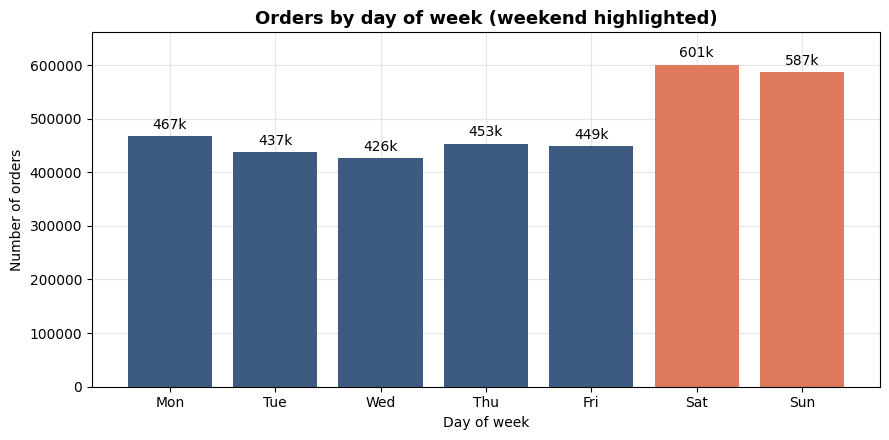

Busiest day: Sat | Weekend share of all orders: 34.7%


In [20]:
orders_by_day = orders["order_dow"].map(DOW_LABELS).value_counts().reindex(DAY_ORDER)
weekend_share = orders["order_dow"].isin(WEEKEND_CODES).mean() * 100

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(orders_by_day.index, orders_by_day.values,
              color=[ORANGE if d in WEEKEND_DAYS else BLUE for d in orders_by_day.index])
ax.bar_label(bars, labels=[f"{v / 1000:,.0f}k" for v in orders_by_day.values], padding=3)
ax.set_title("Orders by day of week (weekend highlighted)")
ax.set_xlabel("Day of week")
ax.set_ylabel("Number of orders")
ax.set_ylim(0, orders_by_day.max() * 1.1)
plt.tight_layout()
plt.show()

print(f"Busiest day: {orders_by_day.idxmax()} | Weekend share of all orders: {weekend_share:.1f}%")

### 3.2 Orders by hour of the day

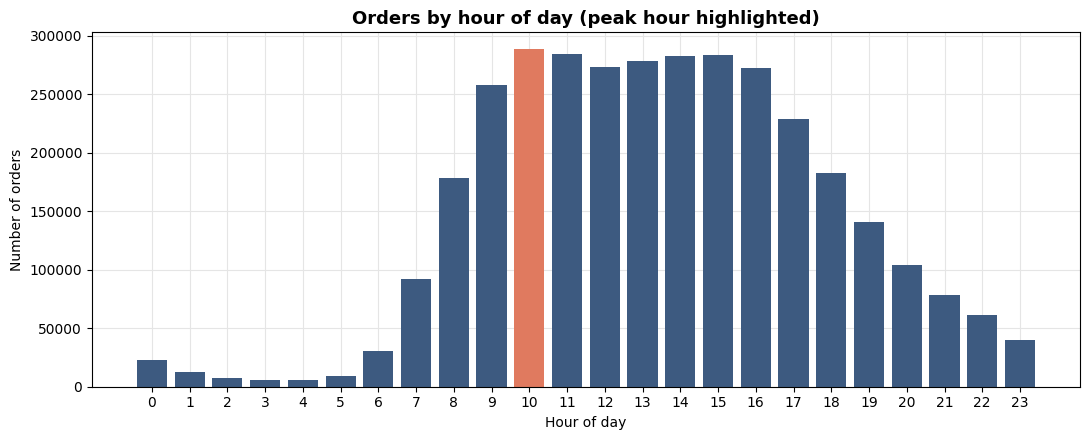

Most common order hour: 10:00


In [21]:
orders_by_hour = orders["order_hour_of_day"].value_counts().sort_index()
peak_hour = int(orders_by_hour.idxmax())

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(orders_by_hour.index, orders_by_hour.values,
       color=[ORANGE if h == peak_hour else BLUE for h in orders_by_hour.index])
ax.set_title("Orders by hour of day (peak hour highlighted)")
ax.set_xlabel("Hour of day")
ax.set_ylabel("Number of orders")
ax.set_xticks(range(24))
plt.tight_layout()
plt.show()

print(f"Most common order hour: {peak_hour}:00")

### 3.3 Day and hour together

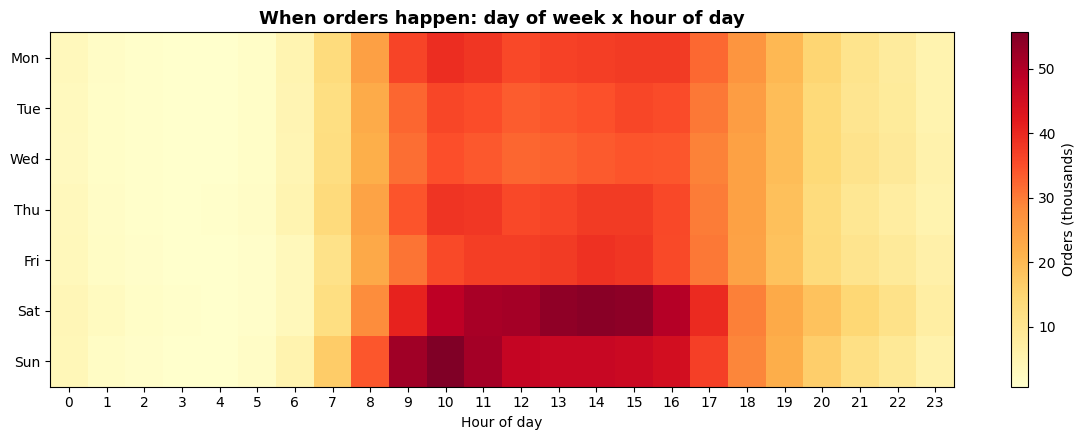

In [22]:
heat = (pd.crosstab(orders["order_dow"].map(DOW_LABELS), orders["order_hour_of_day"])
          .reindex(DAY_ORDER))

fig, ax = plt.subplots(figsize=(12, 4.5))
im = ax.imshow(heat / 1000, cmap="YlOrRd", aspect="auto")
ax.set_xticks(range(heat.shape[1]))
ax.set_xticklabels(heat.columns)
ax.set_yticks(range(heat.shape[0]))
ax.set_yticklabels(heat.index)
ax.grid(False)
fig.colorbar(im, ax=ax, label="Orders (thousands)")
ax.set_title("When orders happen: day of week x hour of day")
ax.set_xlabel("Hour of day")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

### 3.4 Weekend vs weekday shopping rhythm

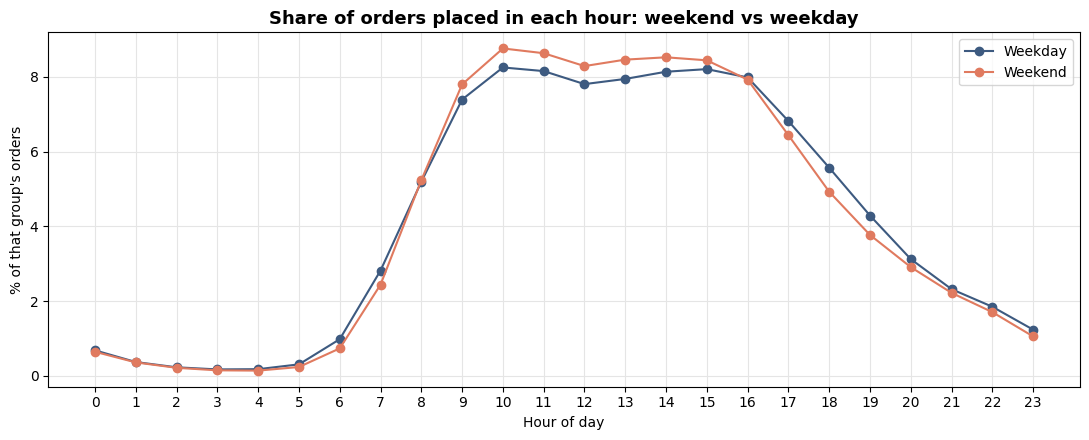

Busiest hour on Saturdays: 14:00


In [23]:
is_weekend = orders["order_dow"].isin(WEEKEND_CODES)
profile = pd.DataFrame({
    "Weekend": orders.loc[is_weekend, "order_hour_of_day"].value_counts(normalize=True).sort_index(),
    "Weekday": orders.loc[~is_weekend, "order_hour_of_day"].value_counts(normalize=True).sort_index(),
}) * 100

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(profile.index, profile["Weekday"], marker="o", color=BLUE, label="Weekday")
ax.plot(profile.index, profile["Weekend"], marker="o", color=ORANGE, label="Weekend")
ax.set_title("Share of orders placed in each hour: weekend vs weekday")
ax.set_xlabel("Hour of day")
ax.set_ylabel("% of that group's orders")
ax.set_xticks(range(24))
ax.legend()
plt.tight_layout()
plt.show()

sat_peak = int(orders.loc[orders["order_dow"] == SATURDAY, "order_hour_of_day"].value_counts().idxmax())
print(f"Busiest hour on Saturdays: {sat_peak}:00")

## 4. How do customers order?

### 4.1 Orders per user

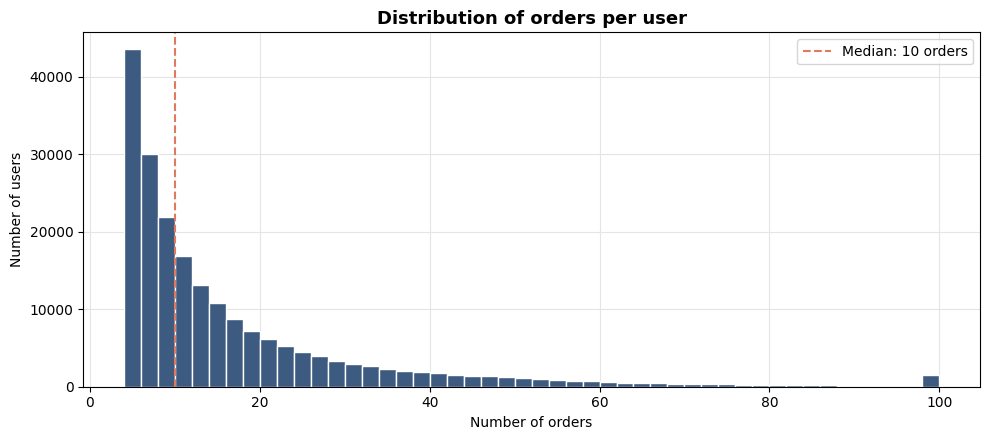

Users: 206,209 | First-time (order_number = 1) orders: 206,209
Maximum orders by one user: 100 (reached by 1,374 users)


In [24]:
orders_per_user = orders.groupby("user_id").size()
max_orders = int(orders_per_user.max())
users_at_max = int((orders_per_user == max_orders).sum())

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist(orders_per_user, bins=48, color=BLUE, edgecolor="white")
ax.axvline(orders_per_user.median(), color=ORANGE, linestyle="--", label=f"Median: {orders_per_user.median():.0f} orders")
ax.set_title("Distribution of orders per user")
ax.set_xlabel("Number of orders")
ax.set_ylabel("Number of users")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Users: {orders_per_user.size:,} | First-time (order_number = 1) orders: {int(first_order.sum()):,}")
print(f"Maximum orders by one user: {max_orders} (reached by {users_at_max:,} users)")

A spike at the maximum usually means order history was truncated at a cap, so the right-hand tail should be read as "at least this many".

### 4.2 Days between orders

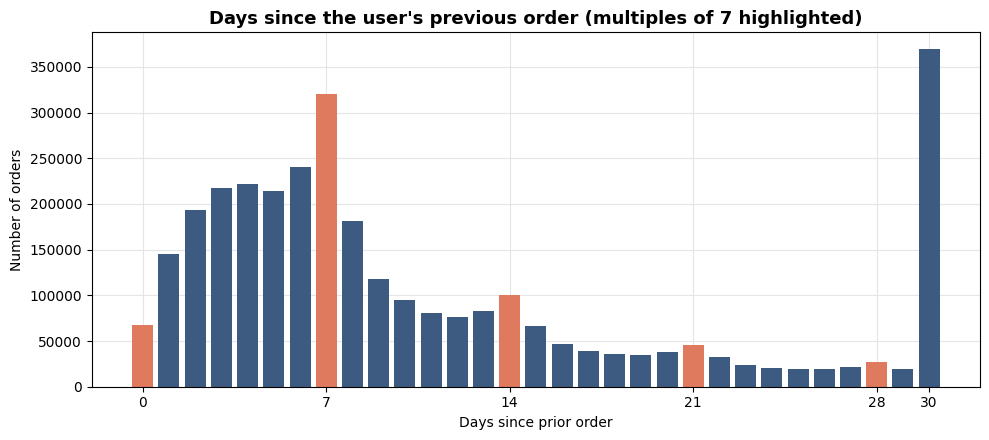

In [25]:
gap_counts = orders["days_since_prior_order"].dropna().value_counts().sort_index()

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(gap_counts.index, gap_counts.values,
       color=[ORANGE if d % 7 == 0 else BLUE for d in gap_counts.index])
ax.set_title("Days since the user's previous order (multiples of 7 highlighted)")
ax.set_xlabel("Days since prior order")
ax.set_ylabel("Number of orders")
ax.set_xticks([0, 7, 14, 21, 28, 30])
plt.tight_layout()
plt.show()

Peaks at 7, 14, 21 and 28 days show a weekly shopping habit. The pile-up at 30 is where longer gaps appear to be capped.

### 4.3 Basket size

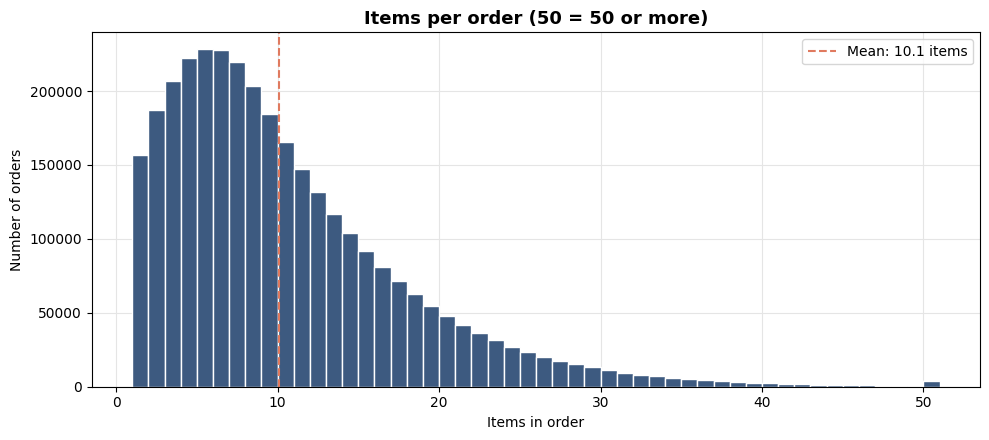

Mean basket: 10.1 items | Median: 8 items


In [26]:
basket_size = order_details.groupby("order_id").size()

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist(basket_size.clip(upper=50), bins=range(1, 52), color=BLUE, edgecolor="white")
ax.axvline(basket_size.mean(), color=ORANGE, linestyle="--", label=f"Mean: {basket_size.mean():.1f} items")
ax.set_title("Items per order (50 = 50 or more)")
ax.set_xlabel("Items in order")
ax.set_ylabel("Number of orders")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Mean basket: {basket_size.mean():.1f} items | Median: {basket_size.median():.0f} items")

## 5. Reordering behavior

`reordered = 1` means the user had bought that product in an earlier order.
Only `prior` orders are used here.

### 5.1 Overall reorder rate

In [27]:
overall_reorder = order_details["reordered"].mean() * 100
print(f"Share of purchased items that were reorders: {overall_reorder:.1f}%")

Share of purchased items that were reorders: 59.0%


### 5.2 Reorder rate by time of day

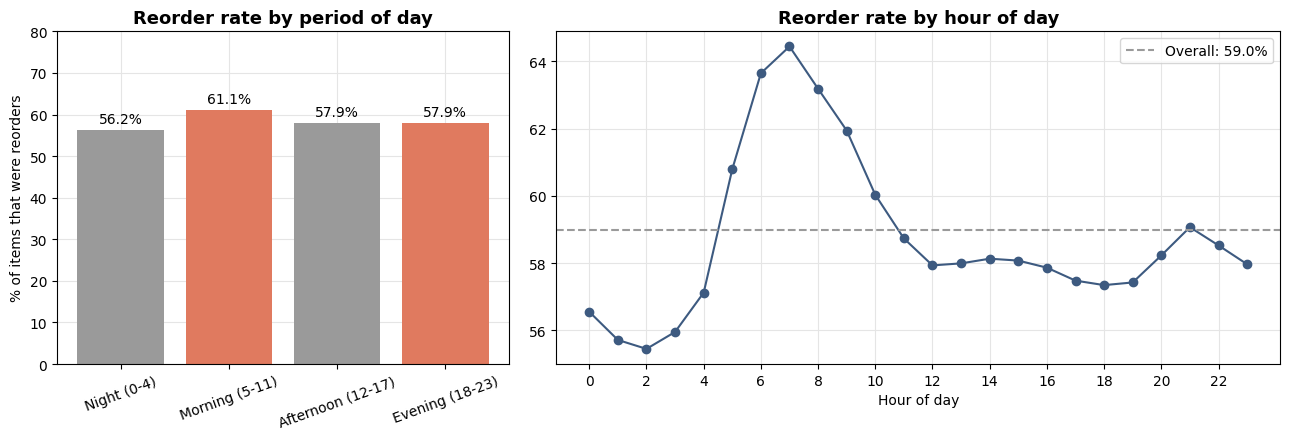

Morning: 61.1% | Evening: 57.9% | Difference: +3.2 percentage points


In [28]:
by_hour = order_details.groupby("order_hour_of_day")["reordered"].agg(["sum", "count"])
by_hour["rate"] = by_hour["sum"] / by_hour["count"] * 100
by_hour["period"] = to_period(by_hour.index)

by_period = by_hour.groupby("period", observed=True)[["sum", "count"]].sum()
by_period["rate"] = by_period["sum"] / by_period["count"] * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1, 1.6]})

bars = axes[0].bar(by_period.index.astype(str), by_period["rate"],
                   color=[ORANGE if p.startswith(("Morning", "Evening")) else GREY for p in by_period.index])
axes[0].bar_label(bars, fmt="%.1f%%", padding=3)
axes[0].set_title("Reorder rate by period of day")
axes[0].set_ylabel("% of items that were reorders")
axes[0].set_ylim(0, 80)
axes[0].tick_params(axis="x", rotation=20)

axes[1].plot(by_hour.index, by_hour["rate"], marker="o", color=BLUE)
axes[1].axhline(overall_reorder, color=GREY, linestyle="--", label=f"Overall: {overall_reorder:.1f}%")
axes[1].set_title("Reorder rate by hour of day")
axes[1].set_xlabel("Hour of day")
axes[1].set_xticks(range(0, 24, 2))
axes[1].legend()
plt.tight_layout()
plt.show()

morning = by_period.loc["Morning (5-11)", "rate"]
evening = by_period.loc["Evening (18-23)", "rate"]
print(f"Morning: {morning:.1f}% | Evening: {evening:.1f}% | Difference: {morning - evening:+.1f} percentage points")

### 5.3 Reorder rate by department

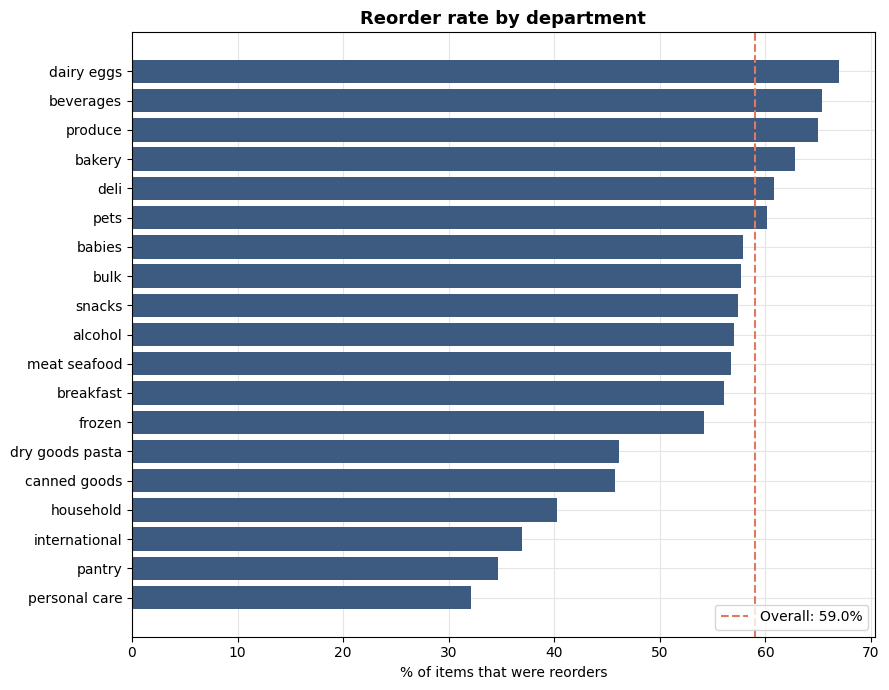

In [29]:
dept_reorder = (order_details.groupby("department", observed=True)["reordered"].mean() * 100)
dept_reorder.index = dept_reorder.index.astype(str)
dept_reorder = dept_reorder.drop(PLACEHOLDER_DEPTS, errors="ignore").sort_values()

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(dept_reorder.index, dept_reorder.values, color=BLUE)
ax.axvline(overall_reorder, color=ORANGE, linestyle="--", label=f"Overall: {overall_reorder:.1f}%")
ax.set_title("Reorder rate by department")
ax.set_xlabel("% of items that were reorders")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

### 5.4 Reorder rate by position in the cart

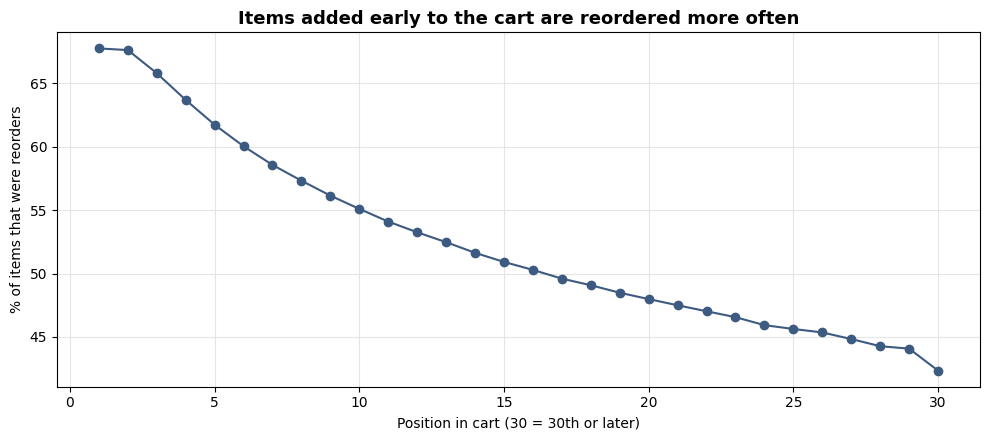

In [30]:
position = order_details["add_to_cart_order"].clip(upper=30)
rate_by_position = order_details.groupby(position)["reordered"].mean() * 100

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(rate_by_position.index, rate_by_position.values, marker="o", color=BLUE)
ax.set_title("Items added early to the cart are reordered more often")
ax.set_xlabel("Position in cart (30 = 30th or later)")
ax.set_ylabel("% of items that were reorders")
plt.tight_layout()
plt.show()

## 6. Products, aisles and departments

### 6.1 Most popular products

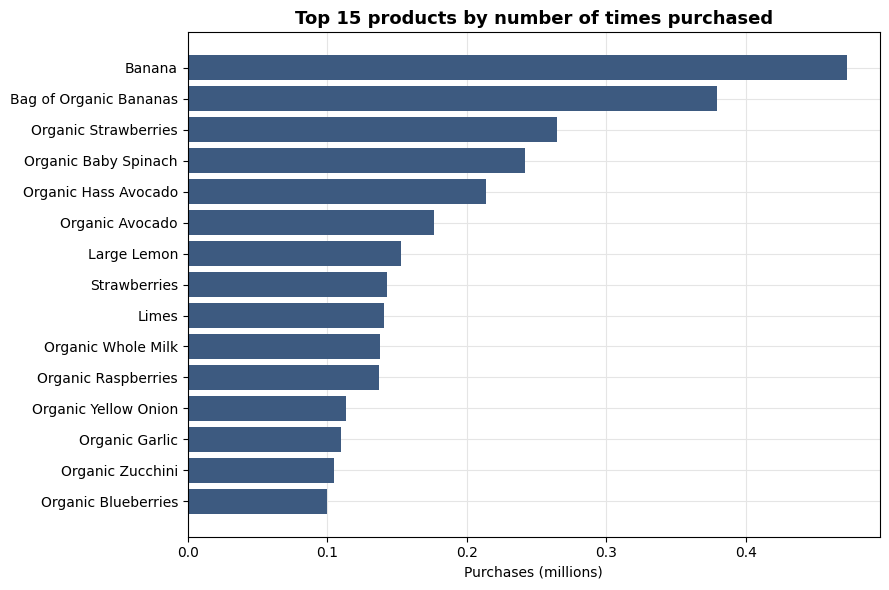

In [31]:
top_products = order_details["product_name"].value_counts().head(15).sort_values()

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top_products.index.astype(str), top_products.values / 1e6, color=BLUE)
ax.set_title("Top 15 products by number of times purchased")
ax.set_xlabel("Purchases (millions)")
plt.tight_layout()
plt.show()

### 6.2 Most popular products on Saturdays

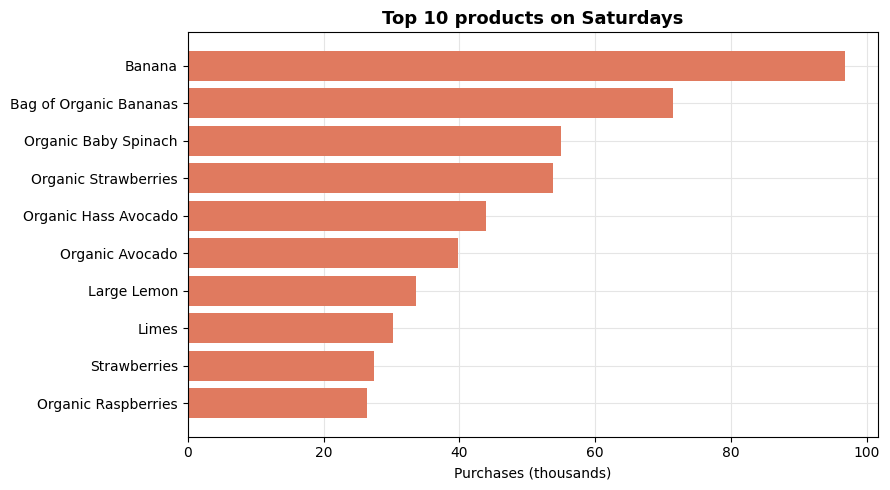

Most popular Saturday product: Banana


In [32]:
sat_top = (order_details.loc[order_details["order_dow"] == SATURDAY, "product_name"]
           .value_counts().head(10).sort_values())

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(sat_top.index.astype(str), sat_top.values / 1000, color=ORANGE)
ax.set_title("Top 10 products on Saturdays")
ax.set_xlabel("Purchases (thousands)")
plt.tight_layout()
plt.show()

print(f"Most popular Saturday product: {sat_top.index[-1]}")

### 6.3 Departments: catalog size vs what people actually buy

The `missing` and `other` departments are placeholders in the source data and are left out of the charts.

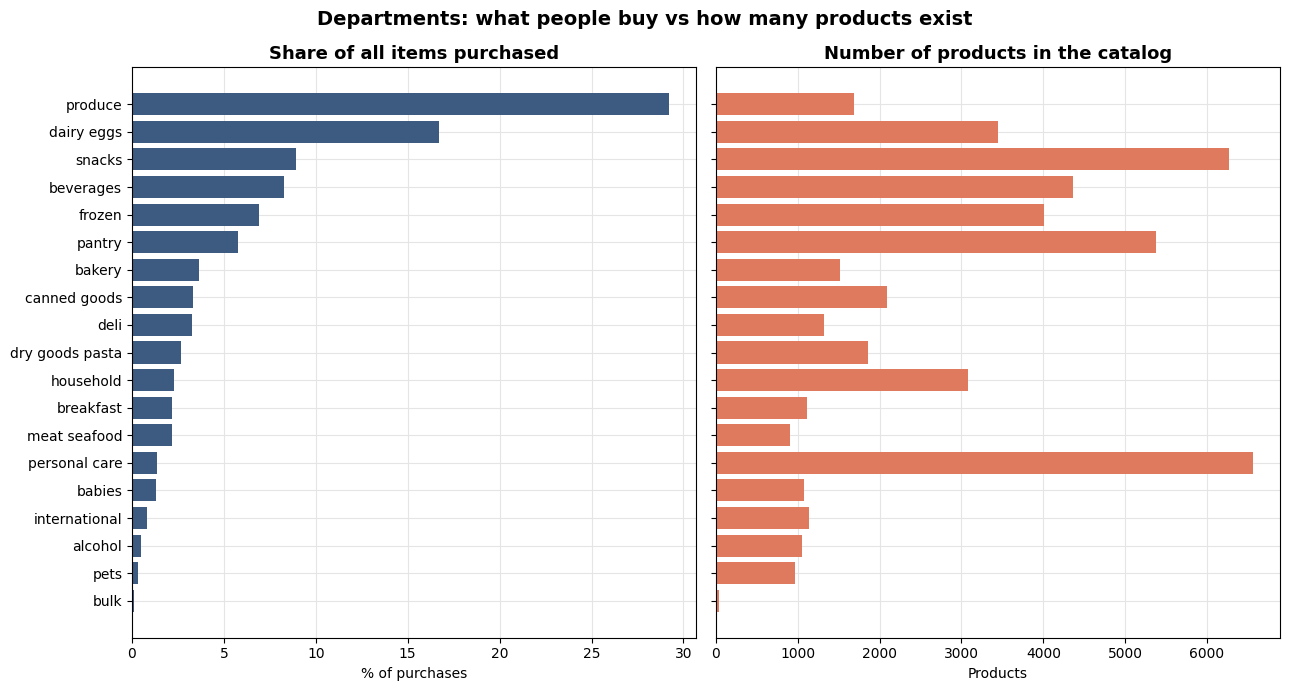

Placeholder departments ('missing' + 'other') account for 0.3% of purchases.


In [33]:
dept_items = order_details["department"].value_counts()
dept_items.index = dept_items.index.astype(str)
dept_share = dept_items / dept_items.sum() * 100

catalog = products_full.groupby("department", observed=True).size()
catalog.index = catalog.index.astype(str)

placeholder_share = dept_share.reindex(PLACEHOLDER_DEPTS).fillna(0).sum()
dept_share = dept_share.drop(PLACEHOLDER_DEPTS, errors="ignore").sort_values()
catalog = catalog.reindex(dept_share.index)

fig, axes = plt.subplots(1, 2, figsize=(13, 7), sharey=True)
axes[0].barh(dept_share.index, dept_share.values, color=BLUE)
axes[0].set_title("Share of all items purchased")
axes[0].set_xlabel("% of purchases")
axes[1].barh(catalog.index, catalog.values, color=ORANGE)
axes[1].set_title("Number of products in the catalog")
axes[1].set_xlabel("Products")
fig.suptitle("Departments: what people buy vs how many products exist", fontweight="bold", fontsize=14)
plt.tight_layout()
plt.show()

print(f"Placeholder departments ('missing' + 'other') account for {placeholder_share:.1f}% of purchases.")

### 6.4 Top aisles

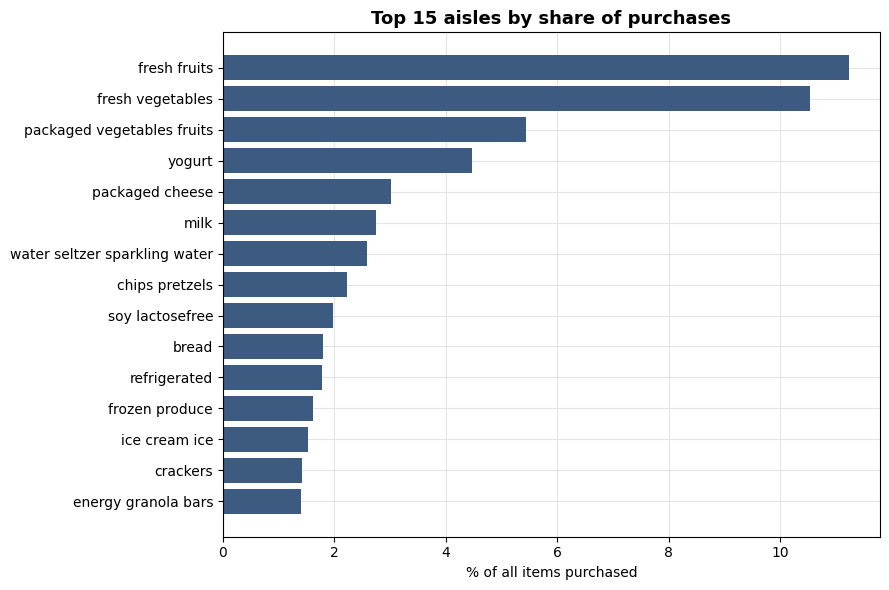

In [34]:
aisle_items = order_details["aisle"].value_counts().head(15).sort_values()
aisle_share = aisle_items / len(order_details) * 100

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(aisle_share.index.astype(str), aisle_share.values, color=BLUE)
ax.set_title("Top 15 aisles by share of purchases")
ax.set_xlabel("% of all items purchased")
plt.tight_layout()
plt.show()

## 7. Summary of findings

In [35]:
summary = {
    "Orders analysed (all eval sets)": f"{len(orders):,}",
    "Prior orders / items purchased": f"{basket_size.size:,} / {len(order_details):,}",
    "Users": f"{orders_per_user.size:,}",
    "Busiest day": orders_by_day.idxmax(),
    "Weekend share of orders": f"{weekend_share:.1f}%",
    "Busiest hour (all days)": f"{peak_hour}:00",
    f"Busiest hour on {DOW_LABELS[SATURDAY]}": f"{sat_peak}:00",
    "Median days between orders": f"{orders['days_since_prior_order'].median():.0f}",
    "Average basket size": f"{basket_size.mean():.1f} items",
    "Overall reorder rate": f"{overall_reorder:.1f}%",
    "Reorder rate, morning vs evening": f"{morning:.1f}% vs {evening:.1f}%",
    "Department with highest reorder rate": dept_reorder.idxmax(),
    "Department with lowest reorder rate": dept_reorder.idxmin(),
    "#1 product overall": str(top_products.index[-1]),
    "#1 product on Saturdays": str(sat_top.index[-1]),
}
pd.Series(summary, name="Value").to_frame()

,Value
Orders analysed (all eval sets),"3,421,083"
Prior orders / items purchased,"3,214,874 / 32,434,489"
Users,"206,209"
Busiest day,Sat
Weekend share of orders,34.7%
Busiest hour (all days),10:00
Busiest hour on Sat,14:00
Median days between orders,7
Average basket size,10.1 items
Overall reorder rate,59.0%


### Next steps

- **Market basket analysis**: find products that are frequently bought together (Apriori / FP-Growth on `order_details`).
- **Customer segmentation**: cluster users by order frequency, basket size and reorder rate.
- **Reorder prediction**: build a model that predicts which previously bought products a user will reorder next.

*Data: "The Instacart Online Grocery Shopping Dataset 2017", accessed from https://www.instacart.com/datasets/grocery-shopping-2017.*